# Differential expression analysis


You have run the nf-core/rnaseq pipeline and checked the first quality control metrics of your fastq files. This was, however, only the primary analysis and we want to take it further.

Due to the computational demand of the pipeline, you only ran the pipeline on two of the 16 samples in the study yesterday. We provide you an essential output of nf-core/rnaseq pipeline in the `data` folder: It contains the combined epression matrix as produced by Salmon, which provides transcript levels for each gene (rows) and each sample (columns).


We would now like to understand exactly the difference between the expression in our groups of mice. 
Which pipeline would you use for this?

- Pipeline: differentialabundance

Have a close look at the pipeline's "Usage" page on the [nf-core docs](nf-co.re). You will need to create a samplesheet (based on the column names in the provided matrix).

In [1]:
import pandas as pd

raw_data = pd.read_csv("data/salmon.merged.gene_counts.tsv", sep = '\t')
print(raw_data.head())

              gene_id gene_name  Sham_oxy_1  Sham_oxy_2  Sham_oxy_3  \
0  ENSMUSG00000000001     Gnai3        69.0       294.0       259.0   
1  ENSMUSG00000000003      Pbsn         0.0         0.0         0.0   
2  ENSMUSG00000000028     Cdc45         1.0        10.0         2.0   
3  ENSMUSG00000000031       H19         0.0         0.0         0.0   
4  ENSMUSG00000000037     Scml2        12.0        21.0        12.0   

   Sham_oxy_4  Sham_Sal_1  Sham_Sal_2  Sham_Sal_3  Sham_Sal_4  SNI_oxy_1  \
0       444.0       242.0       651.0       622.0       406.0      383.0   
1         0.0         0.0         0.0         0.0         0.0        0.0   
2         6.0        15.0        15.0        22.0        12.0        9.0   
3         0.0         0.0         1.0         0.0         0.0        0.0   
4        18.0         9.0        24.0        36.0        19.0       18.0   

   SNI_oxy_2  SNI_oxy_3  SNI_oxy_4  SNI_Sal_1  SNI_Sal_2  SNI_Sal_3  SNI_Sal_4  
0      518.0      349.0      281.0 

In [12]:
# Create the samplesheet
column_names = raw_data.drop(columns=["gene_id", "gene_name"]).columns

# sample,fastq_1,fastq_2,condition,replicate,batch

samplesheet = pd.DataFrame({
    "sample": column_names,
    "condition": column_names.map(lambda x: x.rsplit("_", 1)[0])
})

#samplesheet.set_index("sample")
print(samplesheet.head())
samplesheet.to_csv("data/samplesheet.csv", index=False)

       sample condition
0  Sham_oxy_1  Sham_oxy
1  Sham_oxy_2  Sham_oxy
2  Sham_oxy_3  Sham_oxy
3  Sham_oxy_4  Sham_oxy
4  Sham_Sal_1  Sham_Sal


Please paste here the command you used. You may need to inspect the provided expression matrix more closely and create additional files, like a samplesheet (based on the column names) or a contrast file (there happens to also be one in `data/` that you can use).

In [14]:
##!nextflow run nf-core/differentialabundance -profile test,docker --help

In [18]:
gene_counts_table = pd.read_csv("data/salmon.merged.gene_counts.tsv", sep="\t")
#print(gene_counts_table.head())
print(gene_counts_table.isna().sum())

gene_id       0
gene_name     0
Sham_oxy_1    0
Sham_oxy_2    0
Sham_oxy_3    0
Sham_oxy_4    0
Sham_Sal_1    0
Sham_Sal_2    0
Sham_Sal_3    0
Sham_Sal_4    0
SNI_oxy_1     0
SNI_oxy_2     0
SNI_oxy_3     0
SNI_oxy_4     0
SNI_Sal_1     0
SNI_Sal_2     0
SNI_Sal_3     0
SNI_Sal_4     0
dtype: int64


In [20]:
!nextflow run nf-core/differentialabundance -profile rnaseq,docker -params-file params.yaml -resume

Nextflow 26.10.0 is available - Please consider updating your version to it

 N E X T F L O W   ~  version 26.04.7

NOTE: Your local project version looks outdated - a different revision is available in the remote repository [bc3632310e]
Launching `https://github.com/nf-core/differentialabundance` [modest_chandrasekhar] revision: 5cb5f9858f [master]

WARN: Unrecognized config option 'validation.defaultIgnoreParams'
WARN: Unrecognized config option 'validation.monochromeLogs'

------------------------------------------------------
                                        ,--./,-.
        ___     __   __   __   ___     /,-._.--~'
  |\ | |__  __ /  ` /  \ |__) |__         }  {
  | \| |       \__, \__/ |  \ |___     \`-._,-`-,
                                        `._,._,'
  nf-core/differentialabundance 2.0.0
------------------------------------------------------

[base] Input/output options
  input                       : data/samplesheet.csv
  contrasts                   : data/contras

Explain all the parameters you set and why you set them in this way. If you used or created additional files as input, explain what they are used for.

- docker: to run pipeline inside docker container
- input: path to the samplesheet containing sample ID and condition
- contrast: path to contrast file defining which conditions to compare
- output: path to output directory
- matrix: path to the expression matrix containing the raed counts per gene
- seed: a seed for reproducibility of stochastical processes
- differential_max_pval: maximum p-value threshold for identifying differentially expressed genes (given value in the paper)
- differential_min_fold_change: minimum fold change required to classify a gene as differentially expressed (given value in the paper)


What were the outputs of the pipeline?

- differential abundance report summarizing the main results
- generated plots
- tabular results (e.g. expression analysis from deseq2 tool)
- shinyngs app

Would you exclude any samples? If yes, which and why?

- no

How many genes were differentially expressed in each contrast? Does this confirm what the paper mentions?

PIPELINE:
- SNI_oxy vs. Sham_sal: 1
- SNI_sal vs. Sham_sal: 93
- Sham_oxy vs. Sham_sal: 15


PAPER:
- SNI_oxy vs. Sham_sal: 1012 in NAc, 1116 in mPFC, 533 in VTA
- SNI_sal vs. Sham_sal: 1457 in NAc, 1052 in mPFC, 425 in VTA
- Sham_oxy vs. Sham_sal: 2609 in NAc, 1449 in mPFC, 584 in VTA

The paper mentions differentially expressed genes in three brain regions : the NAc, mPFC and VTA. Briefly explain what these 3 regions are.

- NAc: nucleus accumbens, region in the basal forebrain and central to motivation and addiction
- mPFC: medial prefrontal cortex, region of the frontal cortex involved in decision-making, cognitive control, planning and emotional regulation
- VTA: ventral tegmental area, region in the midbrain containing dopamine-producing neurons that play a key role in reward, motivation and reinforcement learning

Is there anyway from the paper and the material and methods for us to know which genes are included in these regions?

- yes, the RNA-seq data is publicly available on the NCBI Gene Expression Omnibus under accession GSE223541. It can be used to identify which genes are expressed in each region, while the paper primarily reports differentially expressed genes between the defined groups

Once you have your list of differentially expressed genes, do you think just communicating those to the biologists would be sufficient? What does the publication state?

- no, one also has to do a biological interpretation of the results
- gene ontology (GO): analysis for enriched biological processes
- ingenuity pathway analysis (IPA): identification of affected pathways
- upstream regulator (UR) analysis: identification of common upstream regulation factors

Please reproduce the Venn Diagram from Figure 3, not taking into account the brain regions but just the contrasts mentioned.

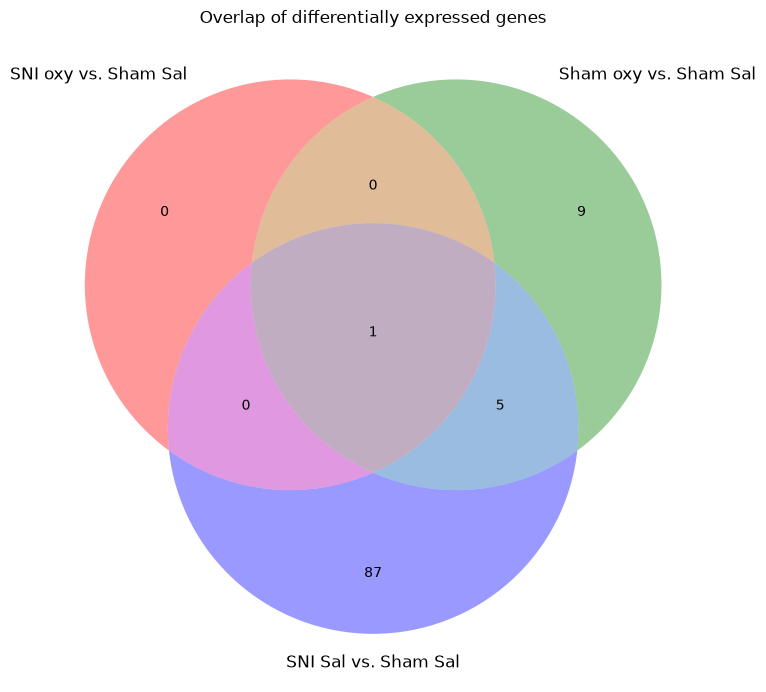

In [26]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib_venn import venn3_unweighted

path = Path("results_differentialabundance/tables/differential/rnaseq")

sni_oxy_vs_sham_sal = pd.read_csv(path/"condition_SNI_oxy_vs_Sham_Sal_study.deseq2.results_filtered.tsv", sep="\t")
sham_oxy_vs_sham_sal = pd.read_csv(path/"condition_Sham_oxy_vs_Sham_Sal_study.deseq2.results_filtered.tsv", sep="\t")
sni_sal_vs_sham_sal = pd.read_csv(path/"condition_SNI_Sal_vs_Sham_Sal_study.deseq2.results_filtered.tsv", sep="\t")

genes_sni_oxy = set(sni_oxy_vs_sham_sal["gene_id"].dropna())
genes_sham_oxy = set(sham_oxy_vs_sham_sal["gene_id"].dropna())
genes_sni_sal = set(sni_sal_vs_sham_sal["gene_id"].dropna())

plt.figure(figsize=(8, 8))

venn3_unweighted(
    [genes_sni_oxy, genes_sham_oxy, genes_sni_sal],
    set_labels=(
        "SNI oxy vs. Sham Sal",
        "Sham oxy vs. Sham Sal",
        "SNI Sal vs. Sham Sal"
    )
)

plt.title("Overlap of differentially expressed genes")
plt.tight_layout()
plt.savefig("results_differentialabundance/venn_diagram.png")
plt.show()

INTERPRETATION:
- oxycodone treatment and withdrawal induces gene expression alteration in pain-free mice
- chronic pain alone indicates a stronger alteration in the gene expression of the mice without oxycodone treatment
- mice receiving a oxycodone withdrawal and having chronic pain do not have a gene expression alteration compared to pain-free and untreated mice, which is contrary to the paper results